# Teste A/B: o impacto de mover o portão de progresso no jogo Cookie Cats

# Contents <a id='back'></a>

* [Introdução](#intro)
* [Etapa 1. Carregando os dados](#data_review)
* [Etapa 2. Validando o experimento](#validation)
* [Etapa 3. Análise exploratória (EDA)](#eda)
* [Etapa 4. Testes de hipóteses para a retenção](#tests)
* [Etapa 5. Bootstrap: a incerteza da diferença](#bootstrap)
* [Etapa 6. Engajamento: rodadas jogadas](#engagement)
* [Etapa 7. Poder estatístico e efeito mínimo detectável](#power)
* [Etapa 8. Abordagem bayesiana](#bayes)
* [Etapa 9. Validando o método com testes A/A](#aa)
* [Etapa 10. Análise por segmento (exploratória)](#segments)
* [Conclusão geral](#end)

## Introdução <a id='intro'></a>

**Cookie Cats** é um jogo de quebra-cabeça para celular da Tactile Entertainment. Em alguns níveis, o jogador encontra um **portão**: para continuar, precisa esperar um tempo ou fazer uma compra. Os portões dão uma pausa ao jogador e criam oportunidades de receita, mas, se aparecerem cedo demais, podem fazer o jogador desistir.

A empresa fez um **teste A/B** para decidir onde colocar o primeiro portão. Os novos jogadores foram divididos aleatoriamente em dois grupos:

- **gate_30 (controle):** o primeiro portão fica no **nível 30**, como no jogo original
- **gate_40 (tratamento):** o primeiro portão é movido para o **nível 40**

### Pergunta de negócio
**Mover o portão do nível 30 para o 40 melhora ou piora a retenção dos jogadores?**

### Métricas
- **Retenção de 7 dias (principal):** o jogador voltou a jogar 7 dias depois de instalar. É a métrica que melhor reflete o valor de longo prazo do jogador.
- **Retenção de 1 dia (secundária):** o jogador voltou no dia seguinte.
- **Rodadas jogadas (engajamento):** total de rodadas nos primeiros 14 dias.

### Objetivo
- Verificar se o experimento foi bem executado
- Testar se há diferença estatisticamente significativa nas métricas, com mais de uma abordagem (frequentista, bootstrap e bayesiana)
- Avaliar o poder estatístico do teste e validar o método
- Recomendar uma decisão para o negócio

### Descrição dos dados
Dados de **90.189 jogadores** que instalaram o jogo durante o teste:

| Coluna | Descrição |
|---|---|
| `userid` | Identificador do jogador |
| `version` | Grupo do teste: `gate_30` ou `gate_40` |
| `sum_gamerounds` | Rodadas jogadas nos primeiros 14 dias após a instalação |
| `retention_1` | O jogador voltou 1 dia depois da instalação? |
| `retention_7` | O jogador voltou 7 dias depois da instalação? |

Fonte: dados do experimento da Tactile Entertainment, disponibilizados publicamente no projeto *Mobile Games A/B Testing with Cookie Cats*.

[Voltar ao Índice](#back)

## Etapa 1. Carregando os dados <a id='data_review'></a>

Se estiver usando o Google Colab ou outro Jupyter online, as bibliotecas abaixo já costumam estar instaladas. Se alguma faltar, basta tirar o `#` da linha de instalação.

In [1]:
# Instalação das bibliotecas (só é necessário se alguma não estiver instalada)
# %pip install pandas numpy matplotlib scipy statsmodels

In [2]:
# Importa as bibliotecas necessárias
import os  # Utilizada para verificar se o arquivo de dados existe na pasta
import warnings  # Utilizada para esconder avisos que não afetam o resultado

import numpy as np  # Utilizada para operações numéricas
import pandas as pd  # Utilizada para manipulação de dados em DataFrames
import matplotlib.pyplot as plt  # Utilizada para a construção de gráficos
from scipy import stats  # Testes estatísticos
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep  # Testes de proporção
from statsmodels.stats.power import NormalIndPower  # Cálculo de poder estatístico
from statsmodels.stats.proportion import proportion_effectsize  # Tamanho de efeito para proporções
from statsmodels.stats.multitest import multipletests  # Correção para múltiplos testes

warnings.filterwarnings("ignore")  # Esconde avisos que não afetam o resultado

# Padroniza a aparência dos gráficos
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, LARANJA, CINZA = "#1f4e79", "#e07b00", "#9aa5b1"
CORES = {"gate_30": AZUL, "gate_40": LARANJA}
rng = np.random.default_rng(42)  # Gerador de números aleatórios com semente fixa, para resultados reproduzíveis

In [3]:
# Caminho do arquivo local e cópia no GitHub (usada se o arquivo não estiver na pasta)
ARQUIVO = "cookie_cats.csv"
URL_GITHUB = "https://raw.githubusercontent.com/gabrieldeoliver1/Projetos/main/Projeto_19/cookie_cats.csv"
if not os.path.exists(ARQUIVO):
    ARQUIVO = URL_GITHUB  # O pandas lê o arquivo direto da internet
    print("Lendo o arquivo do GitHub.")

dados = pd.read_csv(ARQUIVO)
print(f"Jogadores: {len(dados):,}".replace(",", "."))
dados.head()

Jogadores: 90.189


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [4]:
# Verifica tipos, valores ausentes e jogadores duplicados
dados.info()
print(f"\nValores ausentes: {dados.isna().sum().sum()}")
print(f"Jogadores duplicados: {dados['userid'].duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.8 MB

Valores ausentes: 0
Jogadores duplicados: 0


Os dados estão completos: não há valores ausentes nem jogadores repetidos. Cada jogador aparece em apenas um grupo, um requisito básico de um teste A/B.

[Voltar ao Índice](#back)

## Etapa 2. Validando o experimento <a id='validation'></a>

Antes de olhar os resultados, é preciso verificar se o experimento foi bem executado. O primeiro teste é o de **SRM (Sample Ratio Mismatch)**: se os jogadores foram divididos meio a meio, os grupos devem ter tamanhos parecidos. Uma diferença grande demais para ser acaso indica um problema na divisão ou no registro dos dados, o que pode enviesar todo o resultado.

Uso o teste **qui-quadrado** comparando os tamanhos observados com a divisão esperada de 50%/50%.

In [5]:
# Tamanho de cada grupo
tamanhos = dados["version"].value_counts().sort_index()
print(tamanhos.to_string())
print(f"Proporção do gate_30: {tamanhos['gate_30'] / tamanhos.sum():.2%}")

# Teste qui-quadrado: os tamanhos observados são compatíveis com uma divisão de 50%/50%?
esperado = [tamanhos.sum() / 2] * 2
qui2, p_srm = stats.chisquare(tamanhos.values, esperado)
print(f"\nTeste de SRM: qui-quadrado = {qui2:.2f}, valor-p = {p_srm:.4f}")

version
gate_30    44700
gate_40    45489
Proporção do gate_30: 49.56%

Teste de SRM: qui-quadrado = 6.90, valor-p = 0.0086


### Conclusões

- O grupo gate_30 tem **49,56%** dos jogadores, 789 a menos que o gate_40. O valor-p do teste de SRM é **0,0086**, abaixo de 1%: **essa diferença dificilmente é acaso**.
- Em uma empresa, esse é um sinal de alerta: pode haver um problema na atribuição dos grupos ou no registro dos dados, e o ideal é investigar a causa antes de confiar no resultado.
- Os dados não permitem essa investigação (não há data, plataforma ou origem dos jogadores). Por isso, **sigo com a análise, mas registro a ressalva**. O desequilíbrio é pequeno (0,44 ponto percentual em relação a 50%) e só enviesaria o resultado se os jogadores "perdidos" fossem sistematicamente diferentes dos demais.

[Voltar ao Índice](#back)

## Etapa 3. Análise exploratória (EDA) <a id='eda'></a>

### Rodadas jogadas

In [6]:
# Estatísticas descritivas das rodadas jogadas por grupo
dados.groupby("version")["sum_gamerounds"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
version,,,,,,,,
gate_30,44700.0,52.5,256.7,0.0,5.0,17.0,50.0,49854.0
gate_40,45489.0,51.3,103.3,0.0,5.0,16.0,52.0,2640.0


In [7]:
# Os 5 jogadores com mais rodadas
dados.nlargest(5, "sum_gamerounds")

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False
43671,4832608,gate_30,2438,True,True
48188,5346171,gate_40,2294,True,True


Um jogador do grupo gate_30 registrou **49.854 rodadas** em 14 dias, mais de 3.500 rodadas por dia, enquanto o segundo maior valor é cerca de 2.900. Isso é praticamente impossível para um jogador real e indica um **erro de registro** ou um robô. Como esse único valor distorce médias e desvios do grupo, vou removê-lo.

Jogadores após a remoção: 90.188


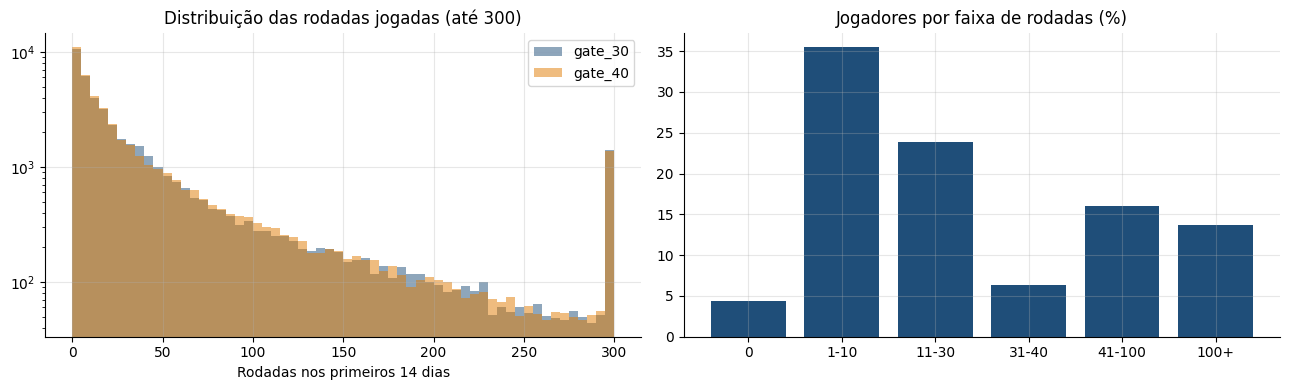

Jogadores que não jogaram nenhuma rodada: 4.4%
Jogadores com 30 rodadas ou menos: 63.8%


In [8]:
# Remove o valor extremo e confirma o tamanho final
dados = dados[dados["sum_gamerounds"] < 10_000].copy()
print(f"Jogadores após a remoção: {len(dados):,}".replace(",", "."))

# Distribuição das rodadas: forte assimetria, por isso uso escala logarítmica no eixo y
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for grupo, cor in CORES.items():
    rodadas = dados.loc[dados["version"] == grupo, "sum_gamerounds"]
    axs[0].hist(rodadas.clip(upper=300), bins=60, alpha=0.5, color=cor, label=grupo)
axs[0].set_yscale("log")
axs[0].set_title("Distribuição das rodadas jogadas (até 300)")
axs[0].set_xlabel("Rodadas nos primeiros 14 dias")
axs[0].legend()

# Quantos jogadores ficam em cada faixa de rodadas: muitos desistem antes de chegar ao nível 30
faixas = pd.cut(dados["sum_gamerounds"], [-1, 0, 10, 30, 40, 100, 10_000],
                labels=["0", "1-10", "11-30", "31-40", "41-100", "100+"])
dist = faixas.value_counts(normalize=True).sort_index() * 100
axs[1].bar(dist.index.astype(str), dist.values, color=AZUL)
axs[1].set_title("Jogadores por faixa de rodadas (%)")
plt.tight_layout()
plt.show()
print(f"Jogadores que não jogaram nenhuma rodada: {(dados['sum_gamerounds'] == 0).mean():.1%}")
print(f"Jogadores com 30 rodadas ou menos: {(dados['sum_gamerounds'] <= 30).mean():.1%}")

A distribuição é **muito assimétrica**: a maioria joga poucas rodadas, e poucos jogam muito. Um ponto importante: **mais da metade dos jogadores joga 30 rodadas ou menos** e, portanto, provavelmente nem chega ao portão. Para esses jogadores, a mudança não faz diferença, o que tende a **diluir** o efeito do teste.

### Retenção por grupo

         retention_1  retention_7
version                          
gate_30        44.82        19.02
gate_40        44.23        18.20


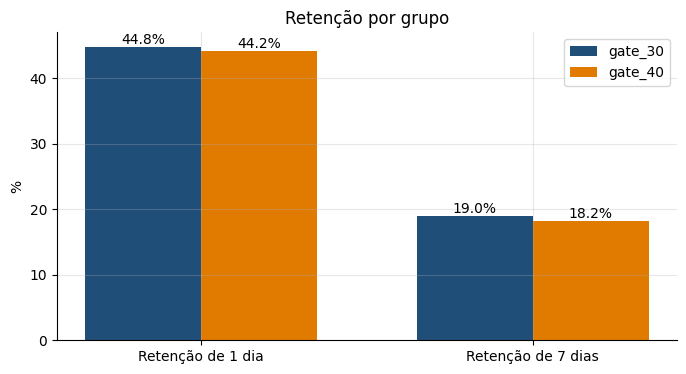

In [9]:
# Taxa de retenção de 1 e 7 dias em cada grupo
retencao = dados.groupby("version")[["retention_1", "retention_7"]].mean() * 100
print(retencao.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(2)
for i, (grupo, cor) in enumerate(CORES.items()):
    valores = retencao.loc[grupo]
    ax.bar(x + (i - 0.5) * 0.35, valores, 0.35, color=cor, label=grupo)
    for xi, v in zip(x + (i - 0.5) * 0.35, valores):
        ax.text(xi, v + 0.5, f"{v:.1f}%", ha="center")
ax.set_xticks(x)
ax.set_xticklabels(["Retenção de 1 dia", "Retenção de 7 dias"])
ax.set_ylabel("%")
ax.set_title("Retenção por grupo")
ax.legend()
plt.show()

O grupo gate_30 tem retenção um pouco maior nas duas métricas. As diferenças parecem pequenas, menos de 1 ponto percentual, e a pergunta é: **essa diferença é real ou pode ser fruto do acaso?** É isso que os testes das próximas etapas respondem.

[Voltar ao Índice](#back)

## Etapa 4. Testes de hipóteses para a retenção <a id='tests'></a>

Para cada métrica de retenção, testo:

- **H0 (hipótese nula):** a retenção é igual nos dois grupos
- **H1 (hipótese alternativa):** a retenção é diferente nos dois grupos

Uso o **teste Z para duas proporções**, adequado para métricas do tipo "sim ou não" com amostras grandes, e um nível de significância de **5%**. Além do valor-p, calculo o **intervalo de confiança de 95% da diferença**, que mostra o tamanho provável do efeito.

In [10]:
ALFA = 0.05


def testar_proporcoes(df, metrica):
    """Teste Z para duas proporções e intervalo de confiança da diferença (gate_40 - gate_30)."""
    a = df.loc[df["version"] == "gate_30", metrica]
    b = df.loc[df["version"] == "gate_40", metrica]
    sucessos, totais = np.array([b.sum(), a.sum()]), np.array([len(b), len(a)])
    z, p = proportions_ztest(sucessos, totais)
    ic_inf, ic_sup = confint_proportions_2indep(sucessos[0], totais[0], sucessos[1], totais[1], method="wald")
    return {"gate_30 (%)": a.mean() * 100, "gate_40 (%)": b.mean() * 100,
            "diferença (p.p.)": (b.mean() - a.mean()) * 100,
            "diferença relativa (%)": (b.mean() / a.mean() - 1) * 100,
            "IC 95% inferior (p.p.)": ic_inf * 100, "IC 95% superior (p.p.)": ic_sup * 100,
            "estatística Z": z, "valor-p": p}


resultados = pd.DataFrame({m: testar_proporcoes(dados, m) for m in ["retention_1", "retention_7"]}).T
resultados.round(4)

,gate_30 (%),gate_40 (%),diferença (p.p.),diferença relativa (%),IC 95% inferior (p.p.),IC 95% superior (p.p.),estatística Z,valor-p
retention_1,44.8198,44.2283,-0.5915,-1.3198,-1.2403,0.0572,-1.7871,0.0739
retention_7,19.0183,18.2000,-0.8183,-4.3028,-1.3263,-0.3103,-3.1574,0.0016


### Conclusões

- **Retenção de 7 dias:** o gate_40 reduz a retenção em **0,82 ponto percentual** (de 19,02% para 18,20%, uma queda relativa de 4,3%). O valor-p é **0,0016** e o intervalo de confiança, de -1,33 a -0,31 ponto percentual, não inclui o zero. **A queda é estatisticamente significativa.**
- **Retenção de 1 dia:** a queda é de 0,59 ponto percentual, mas o valor-p é 0,074 e o intervalo de confiança inclui o zero. **Não há evidência suficiente** de diferença a 5% de significância.

[Voltar ao Índice](#back)

## Etapa 5. Bootstrap: a incerteza da diferença <a id='bootstrap'></a>

O **bootstrap** é uma forma de medir a incerteza sem depender de fórmulas: sorteio, com reposição, novas amostras do mesmo tamanho dos dados originais, calculo a diferença de retenção em cada uma e observo a distribuição dessas diferenças. Faço **5.000 reamostragens**.

retention_1: IC 95% = [-1.23; 0.05] p.p. | P(diferença < 0) = 96.2%
retention_7: IC 95% = [-1.34; -0.32] p.p. | P(diferença < 0) = 99.9%


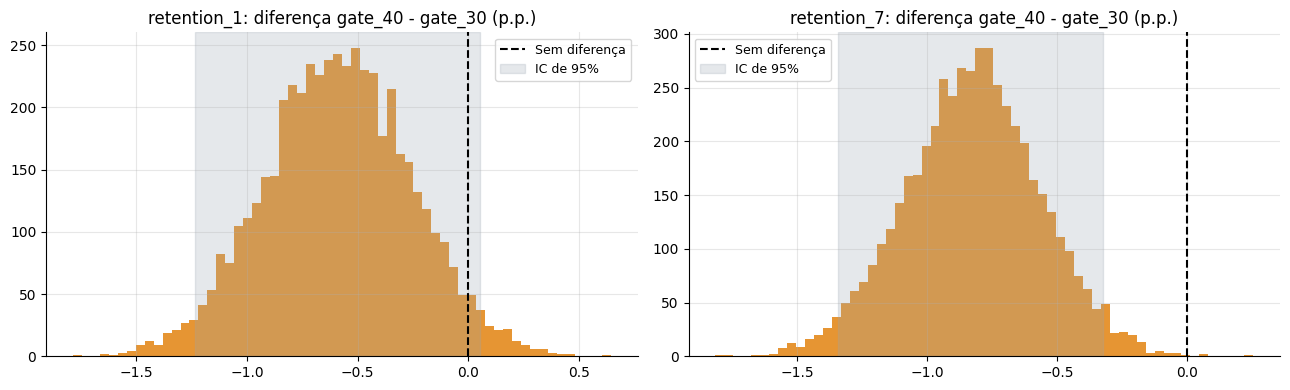

In [11]:
N_BOOT = 5000
grupos = {g: dados[dados["version"] == g] for g in CORES}
diferencas = {"retention_1": [], "retention_7": []}

for _ in range(N_BOOT):
    # Reamostra cada grupo separadamente, mantendo o tamanho original
    amostras = {g: df.iloc[rng.integers(0, len(df), len(df))] for g, df in grupos.items()}
    for m in diferencas:
        diferencas[m].append((amostras["gate_40"][m].mean() - amostras["gate_30"][m].mean()) * 100)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, (m, difs) in zip(axs, diferencas.items()):
    difs = np.array(difs)
    ic = np.percentile(difs, [2.5, 97.5])
    ax.hist(difs, bins=60, color=LARANJA, alpha=0.8)
    ax.axvline(0, color="black", ls="--", lw=1.5, label="Sem diferença")
    ax.axvspan(ic[0], ic[1], color=CINZA, alpha=0.25, label="IC de 95%")
    ax.set_title(f"{m}: diferença gate_40 - gate_30 (p.p.)")
    ax.legend(fontsize=9)
    print(f"{m}: IC 95% = [{ic[0]:.2f}; {ic[1]:.2f}] p.p. | P(diferença < 0) = {(difs < 0).mean():.1%}")
plt.tight_layout()
plt.show()

### Conclusões

O bootstrap confirma os testes da etapa anterior, sem depender de fórmulas:

- **Retenção de 7 dias:** em **99,9%** das reamostragens o gate_40 teve retenção menor, e o intervalo de 95% (de -1,34 a -0,32 ponto percentual) fica inteiro abaixo de zero.
- **Retenção de 1 dia:** em 96,2% das reamostragens o gate_40 foi pior, mas o intervalo de 95% ainda toca o zero.

[Voltar ao Índice](#back)

## Etapa 6. Engajamento: rodadas jogadas <a id='engagement'></a>

As rodadas jogadas têm distribuição muito assimétrica, então o teste t, que supõe distribuição aproximadamente normal, não é o mais adequado. Uso:

- **Teste de Mann-Whitney:** compara as distribuições sem supor normalidade
- **Bootstrap da média e da mediana**, para medir o tamanho da diferença

In [12]:
rodadas_30 = grupos["gate_30"]["sum_gamerounds"]
rodadas_40 = grupos["gate_40"]["sum_gamerounds"]

# Teste de Mann-Whitney (não paramétrico)
estat, p_mw = stats.mannwhitneyu(rodadas_40, rodadas_30, alternative="two-sided")
print(f"Média:   gate_30 = {rodadas_30.mean():.1f} | gate_40 = {rodadas_40.mean():.1f}")
print(f"Mediana: gate_30 = {rodadas_30.median():.0f} | gate_40 = {rodadas_40.median():.0f}")
print(f"Mann-Whitney: valor-p = {p_mw:.4f}")

# Bootstrap da diferença de médias e de medianas
dif_media, dif_mediana = [], []
for _ in range(2000):
    a = rodadas_30.values[rng.integers(0, len(rodadas_30), len(rodadas_30))]
    b = rodadas_40.values[rng.integers(0, len(rodadas_40), len(rodadas_40))]
    dif_media.append(b.mean() - a.mean())
    dif_mediana.append(np.median(b) - np.median(a))
print(f"IC 95% da diferença de médias:   {np.percentile(dif_media, [2.5, 97.5]).round(2)}")
print(f"IC 95% da diferença de medianas: {np.percentile(dif_mediana, [2.5, 97.5]).round(2)}")

Média:   gate_30 = 51.3 | gate_40 = 51.3
Mediana: gate_30 = 17 | gate_40 = 16
Mann-Whitney: valor-p = 0.0509


IC 95% da diferença de médias:   [-1.32  1.29]
IC 95% da diferença de medianas: [-1.  0.]


### Correção para múltiplos testes

Testei três métricas. Quanto mais testes, maior a chance de encontrar uma diferença "significativa" por acaso. A **correção de Holm** ajusta os valores-p para manter a taxa de falsos positivos sob controle.

In [13]:
valores_p = {"retention_1": resultados.loc["retention_1", "valor-p"],
             "retention_7": resultados.loc["retention_7", "valor-p"],
             "sum_gamerounds": p_mw}
rejeita, p_ajustado, _, _ = multipletests(list(valores_p.values()), alpha=ALFA, method="holm")
pd.DataFrame({"valor-p": list(valores_p.values()), "valor-p ajustado (Holm)": p_ajustado,
              "significativo a 5%": rejeita}, index=valores_p.keys()).round(4)

,valor-p,valor-p ajustado (Holm),significativo a 5%
retention_1,0.0739,0.1018,False
retention_7,0.0016,0.0048,True
sum_gamerounds,0.0509,0.1018,False


### Conclusões

- As **médias de rodadas são iguais** nos dois grupos (51,3), e as medianas diferem em apenas 1 rodada. O teste de Mann-Whitney não encontra diferença significativa (valor-p de 0,051).
- Depois da correção de Holm para os três testes, **só a retenção de 7 dias continua significativa** (valor-p ajustado de 0,0048).
- Ou seja: mover o portão não mudou o quanto os jogadores jogam nas primeiras duas semanas, mas reduziu quantos deles continuam jogando depois de 7 dias.

[Voltar ao Índice](#back)

## Etapa 7. Poder estatístico e efeito mínimo detectável <a id='power'></a>

Um teste A/B precisa de amostra suficiente para detectar o efeito que importa para o negócio. Dois conceitos:

- **Poder estatístico:** a probabilidade de o teste detectar um efeito, se ele existir. O padrão é 80%.
- **MDE (efeito mínimo detectável):** a menor diferença que o teste consegue detectar com esse poder.

O ideal é fazer esse cálculo **antes** do teste, para definir a amostra. Aqui, uso-o para entender o que o teste era capaz de detectar.

In [14]:
analise_poder = NormalIndPower()
n_grupo = int(dados["version"].value_counts().min())  # Tamanho do menor grupo
base_7 = grupos["gate_30"]["retention_7"].mean()

# MDE: menor queda na retenção de 7 dias detectável com 80% de poder
efeito_mde = analise_poder.solve_power(nobs1=n_grupo, alpha=ALFA, power=0.8, ratio=1)
# Converte o tamanho de efeito (h de Cohen) em pontos percentuais
mde_pp = (base_7 - np.sin(np.arcsin(np.sqrt(base_7)) - efeito_mde / 2) ** 2) * 100
print(f"Retenção de 7 dias no controle: {base_7:.2%}")
print(f"MDE com {n_grupo:,} jogadores por grupo e 80% de poder: {mde_pp:.2f} p.p.".replace(",", "."))

# Tamanho de amostra necessário para detectar diferentes efeitos
print("\nJogadores necessários por grupo para detectar uma diferença de:")
for dif in [0.25, 0.5, 0.82, 1.0, 2.0]:
    h = proportion_effectsize(base_7, base_7 - dif / 100)
    n = analise_poder.solve_power(effect_size=h, alpha=ALFA, power=0.8, ratio=1)
    print(f"  {dif:.2f} p.p.: {int(np.ceil(n)):>9,} jogadores".replace(",", "."))

Retenção de 7 dias no controle: 19.02%
MDE com 44.699 jogadores por grupo e 80% de poder: 0.73 p.p.

Jogadores necessários por grupo para detectar uma diferença de:
  0.25 p.p.:   384.873 jogadores
  0.50 p.p.:    95.727 jogadores
  0.82 p.p.:    35.355 jogadores
  1.00 p.p.:    23.683 jogadores
  2.00 p.p.:     5.794 jogadores


### Conclusões

- Com cerca de 44.700 jogadores por grupo, o teste conseguia detectar, com 80% de poder, uma diferença a partir de **0,73 ponto percentual** na retenção de 7 dias. A diferença observada, de 0,82, está acima desse limite, então **o teste tinha amostra suficiente** para detectá-la.
- Efeitos menores exigem amostras muito maiores: para detectar 0,25 ponto percentual, seriam necessários **cerca de 385 mil jogadores por grupo**.
- Lição para os próximos testes: definir o MDE relevante para o negócio **antes** de começar e calcular a amostra a partir dele.

[Voltar ao Índice](#back)

## Etapa 8. Abordagem bayesiana <a id='bayes'></a>

O valor-p responde a uma pergunta indireta: "se não houvesse diferença, quão raro seria observar esse resultado?". A abordagem **bayesiana** responde diretamente ao que o negócio quer saber: **"qual a probabilidade de a versão gate_30 ser melhor?"**

Modelo a retenção de cada grupo com uma distribuição **Beta**, a escolha natural para proporções. Começo com uma crença neutra, Beta(1, 1), que é atualizada com os dados de cada grupo. Também calculo a **perda esperada**: quanto de retenção se perde, em média, ao escolher uma versão se ela for, na verdade, a pior.

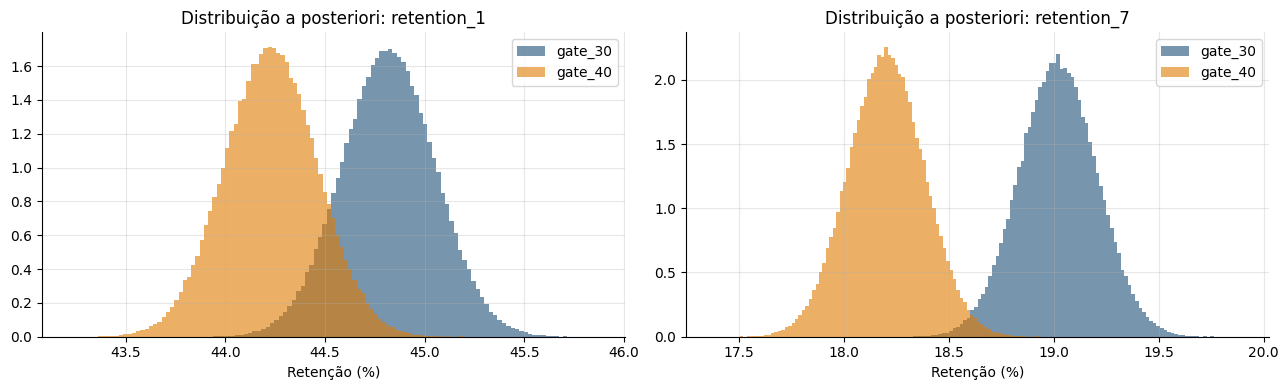

,P(gate_30 é melhor),perda esperada ao escolher gate_40 (p.p.),perda esperada ao escolher gate_30 (p.p.)
retention_1,96.322,0.597,0.005
retention_7,99.922,0.819,0.000


In [15]:
N_SIM = 200_000
resultados_bayes = {}
fig, axs = plt.subplots(1, 2, figsize=(13, 4))

for ax, metrica in zip(axs, ["retention_1", "retention_7"]):
    posteriores = {}
    for grupo, df in grupos.items():
        sucessos, total = df[metrica].sum(), len(df)
        # Posterior Beta(1 + sucessos, 1 + fracassos)
        posteriores[grupo] = rng.beta(1 + sucessos, 1 + total - sucessos, N_SIM)
        ax.hist(posteriores[grupo] * 100, bins=100, alpha=0.6, color=CORES[grupo], density=True, label=grupo)
    dif = posteriores["gate_30"] - posteriores["gate_40"]
    resultados_bayes[metrica] = {
        "P(gate_30 é melhor)": (dif > 0).mean() * 100,
        "perda esperada ao escolher gate_40 (p.p.)": np.maximum(dif, 0).mean() * 100,
        "perda esperada ao escolher gate_30 (p.p.)": np.maximum(-dif, 0).mean() * 100,
    }
    ax.set_title(f"Distribuição a posteriori: {metrica}")
    ax.set_xlabel("Retenção (%)")
    ax.legend()
plt.tight_layout()
plt.show()
pd.DataFrame(resultados_bayes).T.round(3)

### Conclusões

- A probabilidade de o **gate_30 ser melhor** é de **99,9%** na retenção de 7 dias e de 96,3% na de 1 dia.
- Escolher o gate_40 teria uma **perda esperada de 0,82 ponto percentual** na retenção de 7 dias, enquanto escolher o gate_30 tem perda esperada praticamente nula.
- A abordagem bayesiana leva à mesma conclusão que a frequentista, mas em uma linguagem mais fácil de comunicar: "há 99,9% de probabilidade de o portão no nível 30 reter mais jogadores".

[Voltar ao Índice](#back)

## Etapa 9. Validando o método com testes A/A <a id='aa'></a>

Como saber se o método de análise é confiável? Uma forma é fazer **testes A/A**: divido aleatoriamente os jogadores de um mesmo grupo (gate_30) em dois e aplico o mesmo teste. Como os dois "grupos" receberam exatamente a mesma versão, não deveria haver diferença. Repetindo 1.000 vezes, a proporção de resultados significativos deve ficar perto de **5%**, o nível de significância escolhido.

Falsos positivos nos testes A/A: 4.7% (esperado: cerca de 5%)


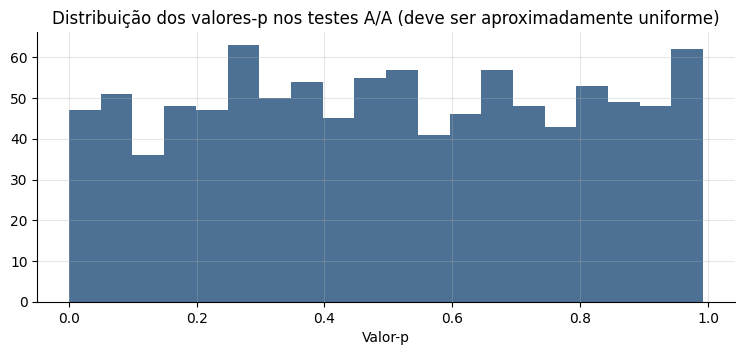

In [16]:
N_AA = 1000
controle = grupos["gate_30"]["retention_7"].values
valores_p_aa = []
for _ in range(N_AA):
    embaralhado = rng.permutation(controle)  # Divisão aleatória em duas metades
    metade_a, metade_b = embaralhado[: len(embaralhado) // 2], embaralhado[len(embaralhado) // 2:]
    _, p = proportions_ztest([metade_a.sum(), metade_b.sum()], [len(metade_a), len(metade_b)])
    valores_p_aa.append(p)

valores_p_aa = np.array(valores_p_aa)
print(f"Falsos positivos nos testes A/A: {(valores_p_aa < ALFA).mean():.1%} (esperado: cerca de 5%)")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(valores_p_aa, bins=20, color=AZUL, alpha=0.8)
ax.set_title("Distribuição dos valores-p nos testes A/A (deve ser aproximadamente uniforme)")
ax.set_xlabel("Valor-p")
plt.show()

### Conclusões

Nos testes A/A, **4,7%** dos resultados foram significativos, muito perto dos 5% esperados, e os valores-p se distribuem de forma aproximadamente uniforme. Isso indica que o método de análise **não gera falsos positivos além do esperado**, o que aumenta a confiança no resultado do teste real.

[Voltar ao Índice](#back)

## Etapa 10. Análise por segmento (exploratória) <a id='segments'></a>

O efeito do portão deveria aparecer principalmente entre os jogadores que **chegam até ele**. Para explorar isso, divido os jogadores pelo número de rodadas jogadas.

**Atenção:** as rodadas jogadas foram medidas **depois** do início do teste e podem ter sido afetadas pela própria mudança do portão. Comparar grupos filtrados por uma variável posterior ao tratamento pode gerar viés, por isso esta análise é apenas **exploratória**: serve para levantar hipóteses, não para tomar a decisão.

In [17]:
dados["segmento"] = pd.cut(dados["sum_gamerounds"], [-1, 30, 40, 10_000],
                          labels=["até 30 rodadas", "31 a 40 rodadas", "mais de 40 rodadas"])
segmentos = (dados.groupby(["segmento", "version"], observed=True)
             .agg(jogadores=("userid", "size"), retencao_7=("retention_7", "mean")).unstack())
segmentos[("retencao_7", "gate_30")] *= 100
segmentos[("retencao_7", "gate_40")] *= 100
segmentos["diferença (p.p.)"] = segmentos[("retencao_7", "gate_40")] - segmentos[("retencao_7", "gate_30")]
segmentos.round(2)

jogadores         retencao_7         diferença (p.p.)
version              gate_30 gate_40    gate_30 gate_40                 
segmento                                                                
até 30 rodadas         28342   29220       4.36    4.04            -0.32
31 a 40 rodadas         3070    2669      16.22   15.81            -0.41
mais de 40 rodadas     13287   13600      50.93   49.09            -1.84

### Conclusões

- A retenção de 7 dias é menor no gate_40 em **todos os segmentos**.
- A maior diferença aparece entre os jogadores com **mais de 40 rodadas**, que passaram pelos dois pontos possíveis do portão: **-1,84 ponto percentual**.
- Uma hipótese é que a pausa forçada no nível 30 ajude a manter o interesse, evitando que o jogador se canse do jogo cedo demais. Por ser uma análise exploratória, essa hipótese precisaria ser confirmada em um novo experimento.

[Voltar ao Índice](#back)

## Conclusão geral <a id='end'></a>

Neste projeto, analisei um teste A/B com **90.188 jogadores** para decidir se o primeiro portão do jogo Cookie Cats deveria ser movido do nível 30 para o 40.

**Principais resultados:**

- **Retenção de 7 dias, a métrica principal:** o portão no nível 40 **reduziu a retenção em 0,82 ponto percentual** (de 19,02% para 18,20%). O resultado é significativo no teste Z (valor-p de 0,0016), no bootstrap, após a correção de Holm para múltiplos testes e na abordagem bayesiana, que dá **99,9% de probabilidade** de o portão no nível 30 ser melhor.
- **Retenção de 1 dia:** queda de 0,59 ponto percentual, sem significância estatística.
- **Engajamento:** as rodadas jogadas não mudaram.
- O teste tinha **poder suficiente** para detectar o efeito observado, e os **testes A/A** confirmaram que o método não gera falsos positivos além do esperado.

**Recomendação para o negócio:** **manter o portão no nível 30.** Mover para o 40 não aumenta o engajamento e reduz a retenção de 7 dias. A cada 100 mil novos jogadores, seriam cerca de **820 jogadores a menos** ativos depois de uma semana.

**Ressalvas e próximos passos:**

- O **teste de SRM** indicou um desequilíbrio entre os grupos que dificilmente é acaso. Antes de uma decisão definitiva, a causa deve ser investigada com a equipe de engenharia.
- Os dados não incluem **receita**. Como os portões também geram compras, o ideal é medir o impacto na monetização antes de decidir.
- Testar outras posições para o portão, como o nível 25, e definir o efeito mínimo relevante e a amostra **antes** do novo teste.

[Voltar ao Índice](#back)